<a href="https://colab.research.google.com/github/anisha-dev26/BIS_LAB-1BF24CS054-/blob/main/TSP_Ant_Colony.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== ACS ==========
Generation   1 | Best Fitness (Distance) = 462.21
Generation   2 | Best Fitness (Distance) = 454.62
Generation   3 | Best Fitness (Distance) = 374.05
Generation   4 | Best Fitness (Distance) = 368.64
Generation   5 | Best Fitness (Distance) = 368.64
Generation   6 | Best Fitness (Distance) = 368.64
Generation   7 | Best Fitness (Distance) = 368.64
Generation   8 | Best Fitness (Distance) = 368.64
Generation   9 | Best Fitness (Distance) = 368.64
Generation  10 | Best Fitness (Distance) = 368.64
Generation  11 | Best Fitness (Distance) = 368.64
Generation  12 | Best Fitness (Distance) = 368.64
Generation  13 | Best Fitness (Distance) = 368.64
Generation  14 | Best Fitness (Distance) = 368.64
Generation  15 | Best Fitness (Distance) = 368.64
Generation  16 | Best Fitness (Distance) = 368.64
Generation  17 | Best Fitness (Distance) = 368.64
Generation  18 | Best Fitness (Distance) = 368.64
Generation  19 | Best Fitness (Distance) = 366.74
Generation  20 | Best F

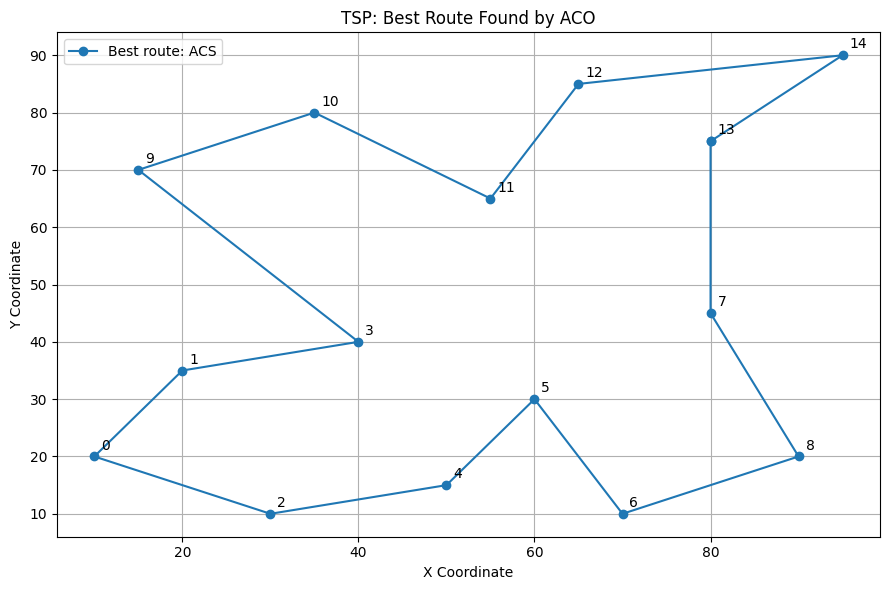

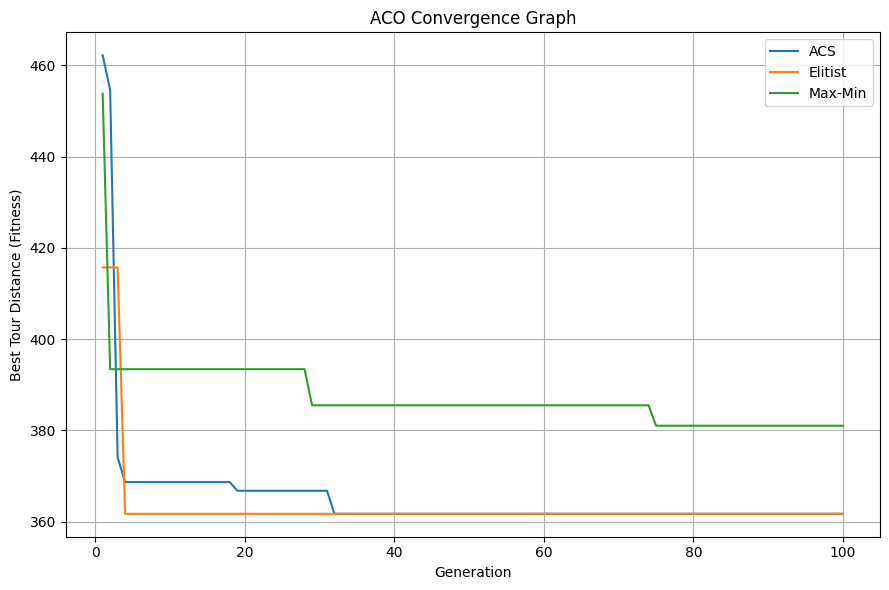

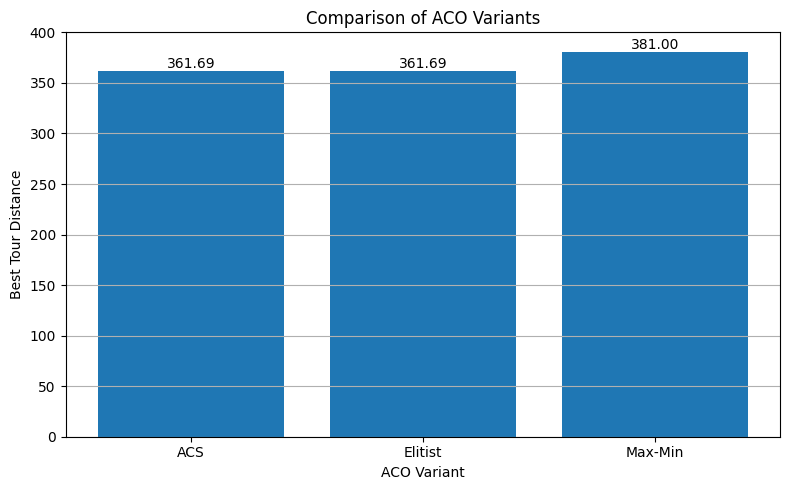

In [2]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# 1. Define 15 cities using (x, y) coordinates
CITIES = np.array([
    [10, 20], [20, 35], [30, 10], [40, 40], [50, 15],
    [60, 30], [70, 10], [80, 45], [90, 20], [15, 70],
    [35, 80], [55, 65], [65, 85], [80, 75], [95, 90]
], dtype=float)

NUM_ANTS = 15
GENERATIONS = 100
ALPHA = 1.0
BETA = 3.0
RHO = 0.9
Q = 1.0
TAU_MIN = 0.01
TAU_MAX = 10.0


# 2. Calculate Euclidean distance between every pair of cities
def calculate_distances(cities):
    difference = cities[:, None, :] - cities[None, :, :]
    distances = np.sqrt(np.sum(difference ** 2, axis=2))
    np.fill_diagonal(distances, 0.0)
    return distances


# 3. Calculate total tour distance (fitness function)
def tour_length(tour, distances):
    total = 0.0

    for i in range(len(tour)):
        current_city = tour[i]
        next_city = tour[(i + 1) % len(tour)]
        total += distances[current_city, next_city]

    return total


# 4. Construct a tour using pheromone and distance information
def construct_tour(pheromone, distances):
    n = len(distances)

    start = np.random.randint(n)
    tour = [start]

    unvisited = set(range(n))
    unvisited.remove(start)

    while unvisited:
        current = tour[-1]
        candidates = sorted(unvisited)

        weights = np.array([
            (pheromone[current, city] ** ALPHA)
            * ((1.0 / max(distances[current, city], 1e-12)) ** BETA)
            for city in candidates
        ])

        total = weights.sum()

        if total == 0 or not np.isfinite(total):
            probabilities = np.ones(len(candidates)) / len(candidates)
        else:
            probabilities = weights / total

        next_city = np.random.choice(candidates, p=probabilities)

        tour.append(next_city)
        unvisited.remove(next_city)

    return tour


# 5. Update pheromone on the edges of a tour
def deposit_pheromone(pheromone, tour, length, amount):
    deposit = amount / max(length, 1e-12)

    for i in range(len(tour)):
        a = tour[i]
        b = tour[(i + 1) % len(tour)]

        pheromone[a, b] += deposit
        pheromone[b, a] += deposit


# 6. Run an ACO variant
def run_aco(method, cities, ants, generations, rho):
    distances = calculate_distances(cities)
    n = len(cities)

    pheromone = np.ones((n, n))
    np.fill_diagonal(pheromone, 0.0)

    best_tour = None
    best_length = float("inf")
    history = []

    print(f"\n========== {method} ==========")

    for generation in range(1, generations + 1):
        tours = []
        lengths = []

        # Each ant constructs a tour
        for _ in range(ants):
            tour = construct_tour(pheromone, distances)
            length = tour_length(tour, distances)

            tours.append(tour)
            lengths.append(length)

            if length < best_length:
                best_length = length
                best_tour = tour.copy()

        # Evaporate existing pheromone
        pheromone *= (1.0 - rho)

        # Pheromone update for each variant
        if method == "ACS":
            for tour, length in zip(tours, lengths):
                deposit_pheromone(pheromone, tour, length, Q)

        elif method == "Elitist":
            for tour, length in zip(tours, lengths):
                deposit_pheromone(pheromone, tour, length, Q)

            # Extra reinforcement for the best tour
            deposit_pheromone(
                pheromone, best_tour, best_length, 5 * Q
            )

        elif method == "Max-Min":
            # Reinforce only the best-so-far tour
            deposit_pheromone(
                pheromone, best_tour, best_length, Q
            )

            pheromone = np.clip(
                pheromone, TAU_MIN, TAU_MAX
            )
            np.fill_diagonal(pheromone, 0.0)

        history.append(best_length)

        print(
            f"Generation {generation:3d} | "
            f"Best Fitness (Distance) = {best_length:.2f}"
        )

    return best_tour, best_length, history


# 7. Run and compare the three ACO variants
results = {}

for method in ["ACS", "Elitist", "Max-Min"]:
    tour, length, history = run_aco(
        method=method,
        cities=CITIES,
        ants=NUM_ANTS,
        generations=GENERATIONS,
        rho=RHO
    )

    results[method] = {
        "tour": tour,
        "length": length,
        "history": history
    }


# 8. Display the final solution
print("\n========== FINAL COMPARISON ==========")

for method, result in results.items():
    closed_tour = result["tour"] + [result["tour"][0]]

    print(f"\nMethod: {method}")
    print("Best Tour:", " -> ".join(map(str, closed_tour)))
    print(f"Minimum Distance: {result['length']:.2f}")

best_method = min(
    results, key=lambda name: results[name]["length"]
)

best_result = results[best_method]
best_tour = best_result["tour"]

print("\n========== FINAL SOLUTION ==========")
print("Best ACO Variant:", best_method)
print(f"Best Tour Distance: {best_result['length']:.2f}")
print(
    "Tour:",
    " -> ".join(map(str, best_tour + [best_tour[0]]))
)


# GRAPH 1: Locations of cities and the best tour
plt.figure(figsize=(9, 6))

closed_tour = best_tour + [best_tour[0]]
route_coordinates = CITIES[closed_tour]

plt.plot(
    route_coordinates[:, 0],
    route_coordinates[:, 1],
    marker="o",
    linestyle="-",
    label=f"Best route: {best_method}"
)

for i, (x, y) in enumerate(CITIES):
    plt.annotate(
        str(i),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("TSP: Best Route Found by ACO")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# GRAPH 2: Convergence of best fitness over generations
plt.figure(figsize=(9, 6))

for method, result in results.items():
    plt.plot(
        range(1, GENERATIONS + 1),
        result["history"],
        label=method
    )

plt.title("ACO Convergence Graph")
plt.xlabel("Generation")
plt.ylabel("Best Tour Distance (Fitness)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# GRAPH 3: Comparison of final best distances
methods = list(results.keys())
final_distances = [
    results[method]["length"] for method in methods
]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, final_distances)

plt.title("Comparison of ACO Variants")
plt.xlabel("ACO Variant")
plt.ylabel("Best Tour Distance")
plt.grid(axis="y")

for bar, value in zip(bars, final_distances):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()
